<div style="padding:32px 36px;background:linear-gradient(120deg,#16334e,#11676c);border-radius:16px;color:white;margin:12px 0 22px">
<div style="font-size:12px;letter-spacing:2px;color:#b8e6e2">NETWORK INTERFERENCE · CODE WALKTHROUGH</div>
<h1 style="color:white;font-size:32px;margin:12px 0">从 1000 名销售员到四状态因果估计</h1>
<p style="font-size:18px;color:#e5f3f4;margin:8px 0">按数据流读懂示例程序</p>
<p style="color:#c2dedf">er_estimation_demo · 连续结果 · 四状态 GMM</p>
</div>

这家公司向部分销售员开放 AI 助手。销售员会与合作伙伴交流，因此业绩同时受自己的处理和同伴处理影响。
我们观察网络、特征、处理和连续业绩，用 PFN 估计四种处理／暴露状态下的平均响应，再与模拟器提供的真值比较。

**本 Notebook 直接调用项目的 DGP、真值计算、模型和训练入口，并配合文字和图表解释计算过程。**

> **当前训练代码统一使用 10 层、128 维 PFN。** 当前保留网络与 DGP 图解，以及另行提供的结果示例；模型输出需加载权重后运行生成。运行第 09 节起的模型计算需要提供匹配的 10 层权重，或主动开启训练。
> `checkpoints/causalpfn_v0.pt` 是比较用的 CausalPFN 基线权重。

**阅读说明**

本 Notebook 以讲解代码流程为主，文字、公式和图表均可直接阅读，无需重新运行或训练模型。
可以在 VS Code 中查看，也可以打开配套 HTML。需要复现计算时，再按项目 README 配置环境并运行代码。

**阅读顺序**

1. 符号说明与代码流程 → 固定 ER 图 → 生成观测数据 → 高低暴露
2. 四状态真值 → 数据划分 → 模型与训练 → 推断与 GMM
3. ITE / ATE 计算 → 正式基线与结果示例 → 换图入口 → 实验配置与结果文件


## 00 · 符号速查：读公式和代码时先看这里

本文统一用 **$A$ 表示邻接矩阵，$T$ 表示处理**。小写 $a$ 是 DGP 中每份数据抽取一次的随机系数；查询里的自身处理状态用小写 $t$。这几个记号不要混用。

### 先用一句话理解高暴露、低暴露

看某个销售员的**直接合作同事中，有多少比例获得 AI 助手**：比例不超过一半，叫低暴露；严格超过一半，叫高暴露。这是当前代码人为规定的暴露分组，既不表示业绩高低，也不改变连续结果 $Y$ 的类型。

例如，4 名同事中 2 人获得 AI 助手，比例为 $2/4=0.5$，仍属低暴露；3 人获得时，比例为 $3/4=0.75$，才属高暴露。**销售员自己是否获得 AI 助手另外用 $T_i$ 表示，不算进这个邻居比例。**

第 04—06 节将用同一个例子说明比例、状态、四个响应和三种效应；下面的表用于随时查符号。

### 图、节点与观测数据

| 符号 | 含义 | 在当前例子中怎么理解 |
|---|---|---|
| $G$ | 网络图 | 销售员之间的合作关系；主实验是固定的 ER 图 |
| $N$ | 节点总数 | 当前固定 ER 图为 1000 个节点 |
| $i,j$ | 节点编号 | $i$ 是当前销售员，$j$ 可以是其合作同事；代码编号从 0 开始 |
| $A=(A_{ij})$ | 邻接矩阵，形状为 $N\times N$ | $A_{ij}=1$ 表示有边，$0$ 表示无边；本例无向且无自环 |
| $\mathcal N_i$ | 节点 $i$ 的邻居集合 | 与第 $i$ 名销售员直接合作的同事 |
| $d_i=\sum_j A_{ij}$ | 节点度数 | 该销售员有多少名合作同事；本例要求 $d_i>0$ |
| $X_i$ | 干预前的节点特征 | 用一个连续变量表示销售员的基础特征 |
| $\overline X_{\mathcal N_i}=\sum_j A_{ij}X_j/d_i$ | 邻居特征均值 | 合作同事的平均基础特征，代码中写作 `neighbor_X` |
| $T_i\in\{0,1\}$ | 实际观察到的自身处理 | 是否向该销售员开放 AI 助手；处理概率为 0.5 |
| $Y_i$、$Y_i^{\mathrm{obs}}$ | 实际观察到的连续结果 | 模拟销售业绩，含有观测噪声；两种写法在这里指同一份观测值 |
| $\epsilon_i$ | 观测噪声 | 当前服从 $\mathcal N(0,4^2)$，标准差为 4 |
| $a$ | 每份任务共享的随机处理系数 | 每份数据抽一次 $a\sim\mathrm{Uniform}(4,8)$，该份数据所有节点共用 |

**两种概率不同：** ER 图的 $p=0.02$ 是“两个节点连边的概率”；$P(T_i=1)=0.5$ 是“某个节点接受处理的概率”。它们分别控制图结构和处理分配。

### 同伴暴露、四状态响应与效应

| 符号 | 含义 | 要注意什么 |
|---|---|---|
| $K_i=\sum_j A_{ij}T_j$ | 接受处理的邻居人数 | 取值为 $0,1,\ldots,d_i$ |
| $E_i=K_i/d_i$ | 实际同伴暴露比例 | 例如 4 名邻居中 3 人接受处理，则 $E_i=0.75$ |
| $S_i=\mathbb 1\{K_i>\lfloor d_i/2\rfloor\}$ | 二元同伴状态 | 严格超过一半为 1；恰好一半归为 0。前述例子中 $S_i=1$ |
| $t,s$ | 查询时指定的自身处理、同伴状态 | 与实际观察到的 $T_i,S_i$ 区分；查询不会改写观测数据 |
| $q=(t,s)$ | 一个状态查询 | 询问该节点在指定状态下的设计平均响应 |
| $b_i=1-X_i-3\overline X_{\mathcal N_i}$ | DGP 的基准响应部分 | 不包含处理项和观测噪声 |
| $\tau_i=a+0.2e^{X_i}$ | 第 06 节中的自身处理系数 | 在当前 DGP 下，也等于该节点的 Direct 真值 |
| $e_{i,s}=\mathbb E[E_i\mid S_i=s]$ | 指定状态内的平均暴露 | 按当前处理设计计算的平均值，不是本次观察到的 $E_i$ |
| $\mu_i(t,s)$ | 节点的四状态平均响应真值 | 固定该任务的图、特征和系数，指定 $t$，再对 $S_i=s$ 内的暴露按设计平均；不含观测噪声 |
| $\widehat\mu_i(t,s)$ | 模型给出的平均响应估计 | 帽子 $\widehat{\phantom\mu}$ 表示“估计值”；与真值比较才能计算误差 |
| $\mu_i^{\mathrm{truth}}(t,s)$ | 显式标注的模拟真值 | 与本表的 $\mu_i(t,s)$ 同义；Oracle 也指模拟器提供的真值 |

四状态按 **`00, 01, 10, 11`** 排列，第一位是自身处理 $t$，第二位是同伴状态 $s$。例如 $\mu_i(1,0)$ 表示“自己接受处理、同伴处于低暴露状态”下的平均响应。**$s=1$ 不表示所有邻居都接受处理，也不表示连续暴露 $E=1$。**

| 效应名称 | 本代码的定义 | 含义 |
|---|---|---|
| Direct | $\mu_i(1,0)-\mu_i(0,0)$ | 同伴低暴露时，改变自身处理的效应 |
| Spillover | $\mu_i(1,1)-\mu_i(1,0)$ | 自身接受处理时，改变同伴状态的效应 |
| Total | $\mu_i(1,1)-\mu_i(0,0)$ | 自身处理与同伴状态一起改变的效应 |

### 模型张量与 GMM 参数

| 符号或代码名 | 含义 |
|---|---|
| $B$ / `batch` | 一批输入中包含的完整网络任务数量，不是节点数 |
| `tokens[B,N,5]` | 每个节点的五维观测输入：$[X_i,T_i,Y_i,E_i,d_i/(N-1)]$ |
| `queries[B,N,4,2]` | 每个节点有 4 个状态查询，每个查询含 $t,s$ 两个坐标 |
| `cepo_target[B,N,4]` | 四个状态的模拟真值，用于训练监督和评测 |
| $h\in\{1,\ldots,5\}$ | 一个 GMM 中的混合分量编号；不是图类型，也不是四状态编号 |
| $\pi_{i,t,s,h}$ / `gmm_pi` | 第 $h$ 个分量的权重；同一节点、同一状态下的 5 个权重之和为 1 |
| $m_{i,t,s,h}$ / `gmm_mu` | 第 $h$ 个高斯分量的均值；不等于整个混合分布的均值 |
| $\sigma_{i,t,s,h}$ / `gmm_sigma` | 第 $h$ 个高斯分量的标准差；与 DGP 的观测噪声标准差 4 不同 |
| $\widehat\mu_i(t,s)=\sum_h\pi_{i,t,s,h}m_{i,t,s,h}$ | 整个 GMM 的均值，作为该响应的点估计 |
| $\mathcal L$ / NLL | 训练损失／负对数似然；本项目对四状态、节点和任务取平均 |

**$\mu_i(t,s)$ 是要估计的响应目标，$m_{i,t,s,h}$ 是模型内部的分量均值。** GMM 描述的是响应目标的预测分布，并不是观测结果 $Y_i$ 的噪声分布。

### 评测下标与常用数学记号

| 记号 | 怎么读 |
|---|---|
| ITE | 本项目中的节点级设计平均效应，每个节点有自己的 Direct、Spillover、Total |
| ATE | 对一份数据中的 $N$ 个节点效应取平均 |
| $r$、$\tau_{ri}$、$\widehat\tau_{ri}$ | 第 12 节中，$r$ 是测试数据集编号；后两个记号表示该数据集第 $i$ 个节点所评估效应的真值和估计值，可分别用于三种效应 |
| MAE / RMSE / Bias | 平均绝对误差／均方根误差／平均带符号误差；本教程误差方向为“预测减真值” |
| $\mathbb E[\cdot]$、$P(\cdot)$ | 期望（平均）与概率；$\mathbb E$ 是数学运算符，$E_i$ 是同伴暴露变量 |
| $\mathbb 1\{\cdot\}$、$\lfloor x\rfloor$ | 条件成立取 1，否则取 0；向下取整 |
| $\sim$、$\mid$、$\sum$ | 服从某个分布；在给定条件下；求和 |
| $e^{X_i}=\exp(X_i)$ | 指数函数，底数为自然常数 $e$；不要与平均暴露 $e_{i,s}$ 混淆 |
| $\mathcal N(m,\sigma^2)$ | 均值为 $m$、方差为 $\sigma^2$ 的正态分布；不同于邻居集合 $\mathcal N_i$ |

接下来读代码时，可以先确认：**这是观测输入、模拟真值，还是模型估计？** 三者在本教程中分开使用。


## 01 · 阅读与运行准备

本 Notebook 已保存讲解所需的图表和结果。**只阅读时无需安装环境或执行代码**，可以直接继续看后面的网络、DGP 和估计流程。

如需重新运行，请先按项目 [README](../README.md) 配置环境，并保留完整项目目录；本文件位于 `er_estimation_demo/notebooks/`。下方代码用于加载依赖和项目源码，阅读时可以跳过。


In [1]:
from pathlib import Path
import sys, json, platform, time

# 从当前目录向上寻找项目；不要手工填写某个人电脑的绝对路径。
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next((p for p in candidates if (p / "pfn_interference/dgp.py").is_file()), None)
if PROJECT is None:
    raise RuntimeError("请从 er_estimation_demo 或其 notebooks 目录打开本文件。")
NOTEBOOK_DIR = PROJECT / "notebooks"
for p in (PROJECT, NOTEBOOK_DIR):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import torch
import networkx as nx
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import pfn_interference.dgp as dgp
from pfn_interference.dgp import generate_task, coefficient_metadata, FORMULA
from pfn_interference.graph import _decode_graph, adjacency_sha256
from pfn_interference.estimands import conditional_count_weights, arm_probability
from pfn_interference.cepo import ARM_NAMES, ARM_COORDINATES, predict_mu_distributions
from pfn_interference.data import TaskBank
from pfn_interference.training import RunConfig, train, load_model
from student_tools import (theme, table, cards, show, factual_frame, conditional_exposures,
                           effects, COLORS, EFFECT_LABELS)

assert Path(dgp.__file__).resolve().parent == PROJECT / "pfn_interference", "内核加载了另一个项目，请重启内核。"
torch.set_num_threads(1)
theme()
FIGURES = NOTEBOOK_DIR / "figures"
RESULTS = NOTEBOOK_DIR / "results"
RESULTS.mkdir(exist_ok=True)
CACHE = NOTEBOOK_DIR / ".cache" / "notebook_tasks"
versions = pd.DataFrame({"项目": ["Python", "PyTorch", "NumPy", "pandas", "NetworkX"],
                         "版本": [platform.python_version(), torch.__version__, np.__version__,
                                  pd.__version__, nx.__version__]})
table(versions)

,项目,版本
0,Python,3.11.16
1,PyTorch,2.14.1
2,NumPy,2.4.6
3,pandas,3.0.6
4,NetworkX,3.6.1


### 全文共用的设置

- `DATA_SEED` 和 `TASK_ID` 确定我们首先观察的那一份测试数据。
- `FOCAL_NODE` 只改变图中重点解释的节点，不改变训练或评测数据。
- `CHECKPOINT_PATH` 指向本版 **10 层、128 维主模型**的权重，默认是 `runs/training/model_best.pt`。仓库未附带该权重；运行模型时需提供匹配权重，或开启训练。
- `RUN_TRAINING=False` 时不会启动任何训练。暂时保持默认，先把流程看完。

In [2]:
DATA_SEED = 2026  # 单份数据讲解用；训练 data_seed 固定为 12345
TASK_ID = 0
FOCAL_NODE = 0
DEVICE = "cpu"  # 推断可用 CPU；训练时按机器选择 cpu / cuda / musa
RUN_TRAINING = False
GRAPH_FILE = PROJECT / "data" / "fixed_er_N1000_p0.02_seed12345.json"
CHECKPOINT_PATH = PROJECT / "runs" / "training" / "model_best.pt"

# 与正式训练入口一致；不会在缺少权重时自动开始训练。
TRAIN_CONFIG = RunConfig(
    graph_file=str(GRAPH_FILE), cache_dir=str(CACHE), device=DEVICE,
    num_layers=10, d_model=128, num_heads=4,
    train_tasks=40960, validation_tasks=5120, epochs=125, batch_size=16,
    data_seed=12345, train_seed=0, noise_sd=4., threads=1,
)


### 一个任务怎么流过程序？

源码集中在 `pfn_interference/`，与 README 一样按下面七步阅读。训练和评测都从项目根目录的 `python -m pfn_interference` 启动。

| 环节 | 输入 | 输出 | 源码入口 |
|---|---|---|---|
| 1. 网络 | 固定图文件 | 邻接矩阵 $A$、度数和图摘要 | [graph.py](../pfn_interference/graph.py) |
| 2. 数据生成 | $A$、种子、任务编号 | $X,T,E,S,Y$ 与模拟真值 | [dgp.py](../pfn_interference/dgp.py) |
| 3. 目标量 | 处理设计与暴露定义 | 四状态响应、直接／溢出／总效应及训练损失 | [estimands.py](../pfn_interference/estimands.py)、[cepo.py](../pfn_interference/cepo.py) |
| 4. 任务划分 | 图、DGP、种子与任务编号 | 可重复的训练／验证／测试任务及缓存 | [data.py](../pfn_interference/data.py) |
| 5. 模型与推断 | 观测数据、$A$、四个查询 | 每个节点、每个状态的 GMM 预测分布 | [model.py](../pfn_interference/model.py) 中的 `LocalNetworkQueryTransformer` |
| 6. 训练 | 完整网络任务、真值与训练配置 | PFN 权重、训练记录和验证曲线 | [training.py](../pfn_interference/training.py) |
| 7. 评测 | 权重、测试任务与独立真值 | PFN／基线的 ITE、ATE 和误差表 | [evaluation.py](../pfn_interference/evaluation.py) |

这个仓库实现**估计实验流程**；识别模块和决策模块位于共同项目的其他部分。


## 02 · 网络：固定的是哪一张图？

本版读取包内保存的 **ER(1000, 0.02)** 图，图种子为 12345，要求无孤立节点。
训练、验证、测试复用这同一张图。正式结果必须以保存的邻接矩阵为准；不同随机库即便 seed 相同，也未必生成同一张图。

下面先核对节点数、边数、度数与 SHA256，再看邻接矩阵和度分布。

### ER 图、处理分配和干扰分别是什么？

- **图**决定“谁与谁有关系”。ER 的连边概率 0.02 用于生成关系，抽好并保存后，本实验不在每个任务里重新连边。
- **处理分配**决定“这一轮谁获得 AI 助手”。固定图上的每个销售员分别以 0.5 的概率接受处理；换一份任务，处理可以重新抽取。
- **干扰**指别人的处理会影响自己的结果。当前 DGP 用邻居接受处理的比例来描述这条影响路径。

所以一张图可以承载很多次不同的处理分配；图的密度与某次分配产生的高／低暴露，是两件事。


,图,连边概率 p,图种子,实际密度,连通分量
0,包内固定 ER1000,0.0200,12345,0.0198,1


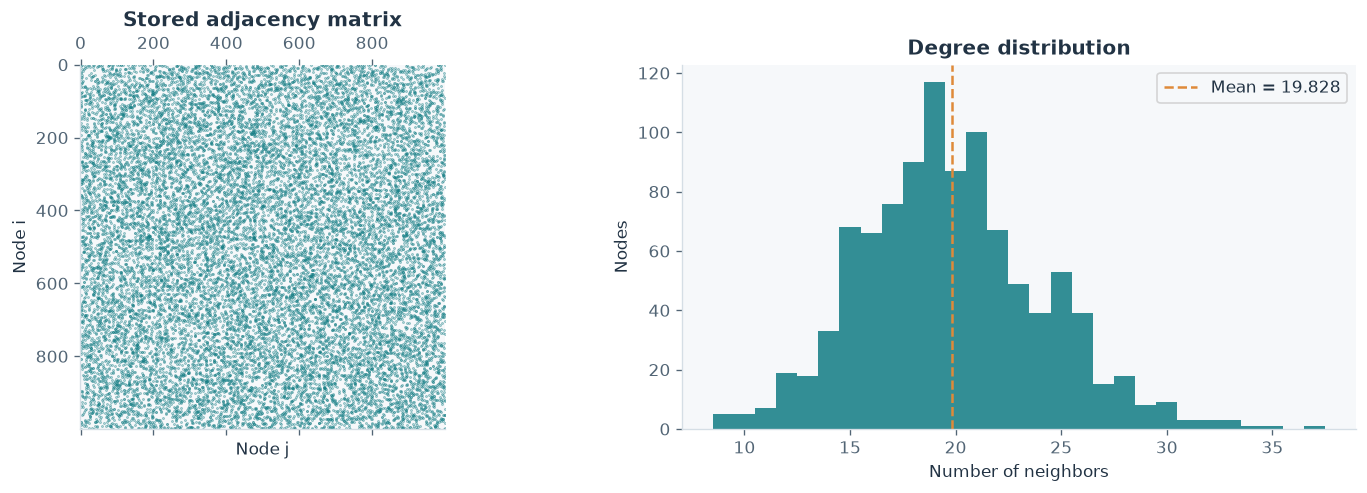

In [3]:
graph_record = json.loads(GRAPH_FILE.read_text(encoding="utf-8"))
A = _decode_graph(graph_record["n_units"], graph_record["upper_hex"]).clone()
assert adjacency_sha256(A) == graph_record["adjacency_sha256"]
assert torch.equal(A, A.T) and not A.diag().any()
N = A.shape[0]
degree = A.sum(1).numpy().astype(int)
G = nx.from_numpy_array(A.numpy())
assert N == 1000 and degree.min() > 0
cards([("节点 N", N), ("实际边数", G.number_of_edges()),
       ("平均度", f"{degree.mean():.3f}"), ("度数范围", f"{degree.min()}–{degree.max()}")])
table(pd.DataFrame([{"图": "包内固定 ER1000", "连边概率 p": graph_record["edge_probability"],
                     "图种子": graph_record["seed"], "实际密度": nx.density(G),
                     "连通分量": nx.number_connected_components(G)}]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].spy(A.numpy(), markersize=.12, color=COLORS[0])
axes[0].set(title="Stored adjacency matrix", xlabel="Node j", ylabel="Node i")
axes[1].hist(degree, bins=np.arange(degree.min()-.5, degree.max()+1.5), color=COLORS[0], alpha=.85)
axes[1].axvline(degree.mean(), color=COLORS[1], linestyle="--", label=f"Mean = {degree.mean():.3f}")
axes[1].set(title="Degree distribution", xlabel="Number of neighbors", ylabel="Nodes")
axes[1].legend()
show(fig, FIGURES, "01_graph_overview")

**怎么看图？** 左侧的一个点表示两名销售员有合作关系；对称性对应无向网络。右侧是每人合作同事数量的分布。
$p=0.02$ 是生成时每条候选边的概率，不是处理分配概率。处理分配仍是 $P(T_i=1)=0.5$。

## 03 · DGP：一份观测数据到底怎么生成？

每个模拟任务抽取一次 $a\sim\mathrm{Uniform}(4,8)$，该任务所有节点共享它。

$$
\begin{aligned}
X_i&\sim N(0,1),\qquad T_i\sim\mathrm{Bernoulli}(0.5),\\
\overline X_{\mathcal N_i}&=\frac{\sum_j A_{ij}X_j}{d_i},\qquad
E_i=\frac{\sum_j A_{ij}T_j}{d_i},\\
Y_i&=1-X_i-3\overline X_{\mathcal N_i}
 +(a+0.2e^{X_i})T_i-0.9E_i+\epsilon_i,\\
\epsilon_i&\sim N(0,4^2).
\end{aligned}
$$

| 项 | 在例子中的含义 |
|---|---|
| $1-X_i-3\overline X_{\mathcal N_i}$ | 不含处理的基准业绩部分 |
| $(a+0.2e^{X_i})T_i$ | 自己获得 AI 助手带来的贡献 |
| $-0.9E_i$ | 合作同事的处理比例带来的溢出贡献 |
| $\epsilon_i$ | 观测噪声 |

负溢出是本次模拟设定，例如合作同事使用 AI 后产生竞争；它不是对现实 AI 助手影响的经验结论。
$a$ 在讲解模拟器时可以查看，但它和反事实真值都不会作为模型的输入特征。

### 这段 DGP 与模型估计是什么关系？

DGP 是“模拟数据生成机制”：程序先规定一条公式，生成我们能观察到的 $X,T,Y$，再利用已知公式独立计算真值。PFN 的任务是从观测数据估计这些真值；测试时不会把公式中的隐藏系数 $a$ 或真值作为输入特征交给它。

请分清：**$Y_i$ 是本次实际分配下的一次含噪观测，$mu_i(t,s)$ 是指定状态下的平均响应。** 因此，后面画“预测与真值”的图时，比较的是 $widehatmu$ 与 $mu$，不是直接要求预测数值等于本次 $Y_i$。


In [4]:
task = generate_task(A, seed=DATA_SEED, task_id=TASK_ID,
                     stream="scaling_v1/test", noise_sd=4.0)
batch = task.batch
observed = factual_frame(batch)
a = task.metadata["a"]  # 仅用于解释和核对模拟器
noise = batch["noise"][0].numpy()
factual_mean = (1-observed["X"]-3*observed["neighbor_X"]
                +(a+.2*np.exp(observed["X"]))*observed["T"]-.9*observed["E"])
np.testing.assert_allclose(observed["Y"], factual_mean+noise, rtol=1e-5, atol=1e-5)
cards([("本任务的 a（仅模拟器）", f"{a:.4f}"),
       ("获得处理的节点", int(observed["T"].sum())),
       ("观测 Y 平均值", f"{observed['Y'].mean():.3f}"),
       ("观测噪声标准差", "4.0")])
table(observed.head(10))

,node,X,T,Y,degree,K,E,S,neighbor_X,degree_norm
0,0,-0.7389,1,4.9224,24,12,0.5000,0,0.3354,0.0240
1,1,1.6658,0,-2.3987,26,12,0.4615,0,0.0704,0.0260
2,2,-0.3741,1,16.9629,19,6,0.3158,0,-0.0509,0.0190
3,3,-0.0038,0,0.3495,14,8,0.5714,1,0.7135,0.0140
4,4,-0.0423,0,-3.0352,21,7,0.3333,0,-0.1154,0.0210
5,5,1.3395,1,8.5241,18,8,0.4444,0,-0.1080,0.0180
6,6,0.5265,1,9.2795,15,5,0.3333,0,0.2472,0.0150
7,7,0.3457,0,-3.1004,20,10,0.5000,0,0.2175,0.0200
8,8,0.3010,0,3.4929,15,7,0.4667,0,-0.2560,0.0150
9,9,1.2048,0,-3.7516,15,9,0.6000,1,0.0927,0.0150


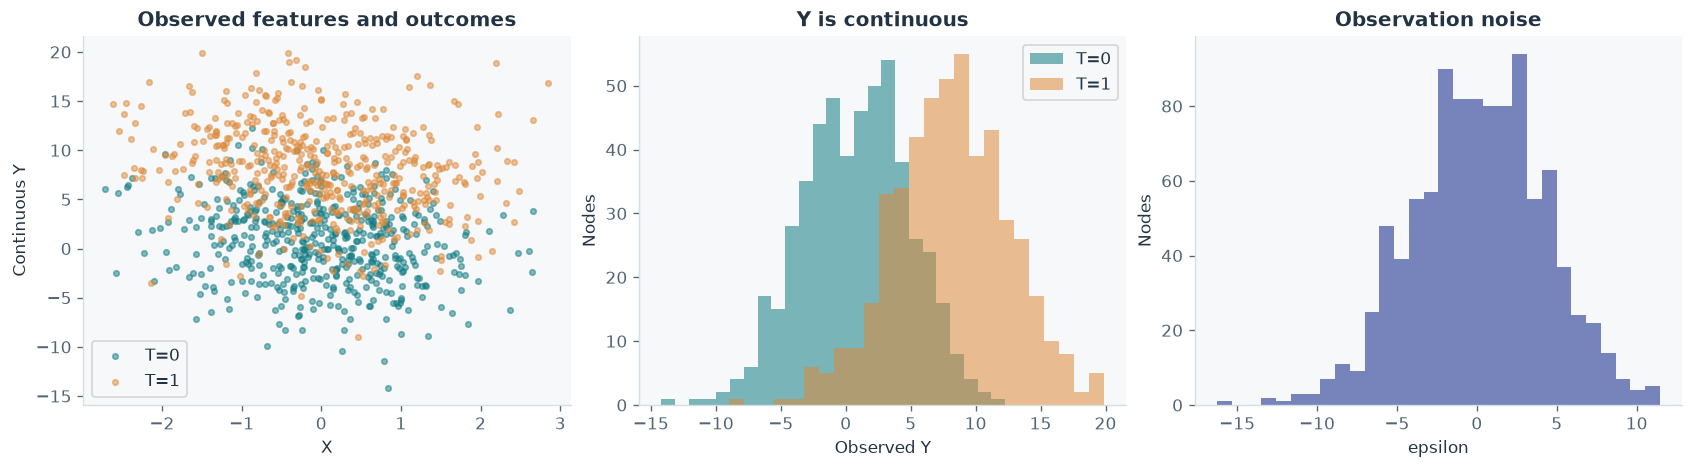

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for t in (0, 1):
    sub = observed[observed["T"] == t]
    axes[0].scatter(sub["X"], sub["Y"], s=11, alpha=.5, color=COLORS[t], label=f"T={t}")
    axes[1].hist(sub["Y"], bins=25, alpha=.55, color=COLORS[t], label=f"T={t}")
axes[0].set(title="Observed features and outcomes", xlabel="X", ylabel="Continuous Y")
axes[0].legend()
axes[1].set(title="Y is continuous", xlabel="Observed Y", ylabel="Nodes")
axes[1].legend()
axes[2].hist(noise, bins=30, color=COLORS[2], alpha=.8)
axes[2].set(title="Observation noise", xlabel="epsilon", ylabel="Nodes")
show(fig, FIGURES, "02_observed_data")

**这里的处理组与对照组散点用于理解数据。** 直接把两组观测均值相减，并不能替代我们定义的节点条件响应和三种效应的估计。

## 04 · 高暴露、低暴露：到底在说什么？

### 第一步：把“自己接受处理”与“邻居接受处理”分开

仍以公司向销售员开放 AI 助手为例。看销售员小李时，我们分别问：

1. **小李自己有没有获得 AI 助手？** 用 $T_i$ 表示，获得为 1，否则为 0。
2. **小李的直接合作同事中，有多大比例获得了 AI 助手？** 用同伴暴露 $E_i$ 表示。

这里“暴露”指接触到接受处理的同伴这一关系条件。当前代码用合作网络和处理分配来计算它，没有另外观测消息次数或实际 AI 使用频率。

先数同事总数 $d_i$，再数其中接受处理的人数 $K_i$，最后相除：

$$
K_i=\sum_j A_{ij}T_j,\qquad
E_i=\frac{K_i}{d_i}.
$$

没有自环，所以计算 $E_i$ 时**不把小李自己算进去**。固定邻居处理不变时，仅改变自己的 $T_i$ 不会改变自己的 $E_i$；但这可能改变邻居们的暴露。

### 第二步：把比例分为低、高两个状态

本版采用“严格多数”的分界规则：

$$
S_i=\begin{cases}
0,&E_i\leq 0.5\quad\text{（低暴露）},\\
1,&E_i>0.5\quad\text{（高暴露）}.
\end{cases}
$$

等价的整数写法是 $S_i=\mathbb 1\{K_i>\lfloor d_i/2\rfloor\}$。代码里的 `degree // 2` 是向下取整；高暴露要求邻居处理人数严格超过这个数。

下面假设小李恰好有 **4 名合作同事**，只用于讲解规则，并不替换 ER1000 主实验。**● = 同事接受处理，○ = 同事未接受处理**。

| 四名同事的处理情况 | 处理人数 $K_i$ | 比例 $E_i=K_i/4$ | 状态 $S_i$ | 为什么 |
|---|---:|---:|---|---|
| ○ ○ ○ ○ | 0 | 0 | 低暴露，0 | 无同事接受处理 |
| ● ○ ○ ○ | 1 | 0.25 | 低暴露，0 | 未超过一半 |
| ● ● ○ ○ | 2 | 0.50 | **低暴露，0** | **恰好一半，也归入低暴露** |
| ● ● ● ○ | 3 | 0.75 | 高暴露，1 | 严格超过一半 |
| ● ● ● ● | 4 | 1 | 高暴露，1 | 所有同事接受处理 |

若有 5 名同事，0—2 人接受处理为低暴露，3—5 人为高暴露。分类看的是**比例**：同样有 2 人接受处理，2/4 属于低暴露，2/3 就属于高暴露。

这里把 $E_i$ 称为“连续暴露”是为了与二元状态 $S_i$ 区分，表示保留比例数值；固定 $d_i$ 后，它实际只能取 $0,1/d_i,\ldots,1$ 这些有限的值。原 DGP 仍使用 $E_i$，没有把它替换成 $S_i$。

### 第三步：与自身处理组合成四种状态

| 查询 $(t,s)$ | 自身情况 | 同伴情况 | 想估计的响应 |
|---|---|---|---|
| $(0,0)$ | 小李未获得 AI 助手 | 同事中不超过一半获得 | $\mu_i(0,0)$ |
| $(0,1)$ | 小李未获得 AI 助手 | 同事中超过一半获得 | $\mu_i(0,1)$ |
| $(1,0)$ | 小李获得 AI 助手 | 同事中不超过一半获得 | $\mu_i(1,0)$ |
| $(1,1)$ | 小李获得 AI 助手 | 同事中超过一半获得 | $\mu_i(1,1)$ |

一份数据里，每个节点只有一个实际观察到的 $(T_i,S_i)$ 和一个 $Y_i$。模型要回答的则是四种状态各自的平均响应。**这不是把节点或业绩分为四类的分类任务；四个输出都是连续响应的估计。**

### 这里最容易混淆的几个意思

- 低暴露不是“完全没有同伴接受处理”，高暴露也不是“全部同伴接受处理”。
- 高暴露不表示业绩更高，也不表示效果更好。当前模拟式中同伴项是 $-0.9E_i$，所以在其他条件相同时，较高暴露会降低平均响应。
- 高暴露不是稠密图。一个节点的邻居可以很少，但多数接受处理，仍然属于高暴露。
- 0.5 是本版本选定的分类阈值，不是 PFN 学出来的值。处理概率也恰好为 0.5，但两者是不同的设定。
- 改阈值会改变状态分组和相应目标，真值、训练查询与基线都要一起核对，不能只改表格中的名称。

下面回到原 ER1000 数据，用实际节点展示邻居和处理比例。`FOCAL_NODE` 仅用于选择要观察的节点。


,节点,自身处理 T,邻居数 d,已处理邻居数 K,比例 E,多数状态 S,连续业绩 Y
0,0,1,24,12,0.5000,0,4.9224


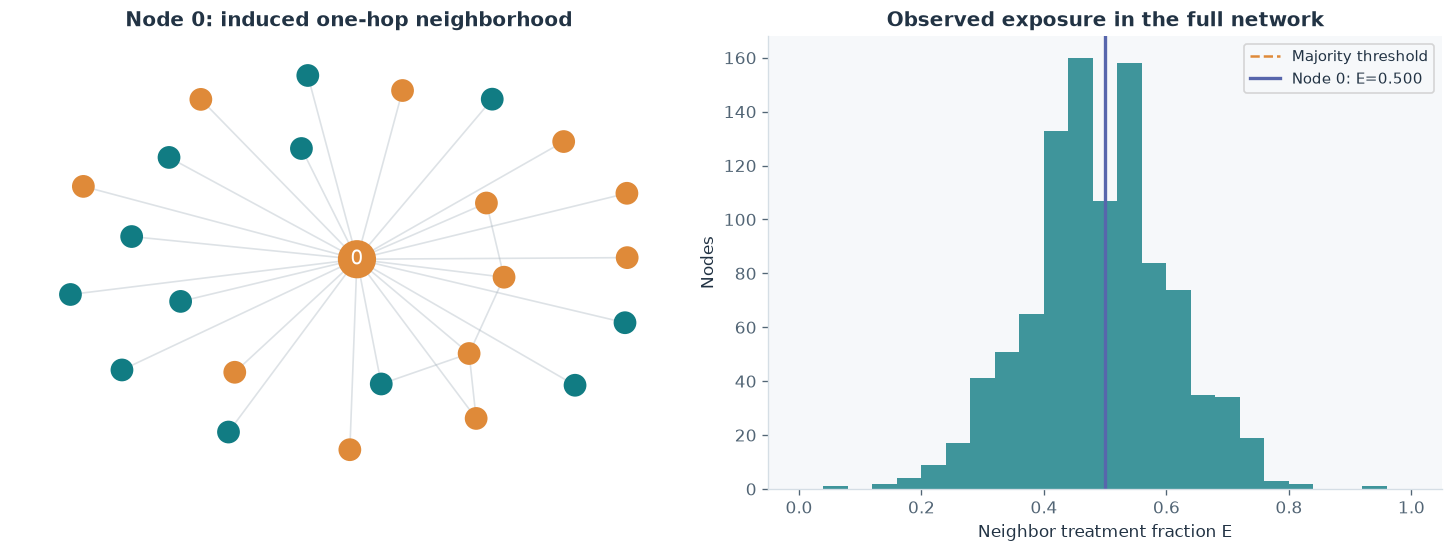

In [6]:
assert 0 <= FOCAL_NODE < N
i = FOCAL_NODE
neighbors = np.flatnonzero(A[i].numpy())
node = observed.iloc[i]
assert int(observed.loc[neighbors, "T"].sum()) == int(node["K"])
table(pd.DataFrame([{"节点": i, "自身处理 T": int(node['T']), "邻居数 d": int(node['degree']),
                     "已处理邻居数 K": int(node['K']), "比例 E": node['E'],
                     "多数状态 S": int(node['S']), "连续业绩 Y": node['Y']}]))
local_nodes = [i, *neighbors.tolist()]
subgraph = G.subgraph(local_nodes)
pos = nx.spring_layout(subgraph, seed=7)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
nx.draw_networkx_edges(subgraph, pos, ax=axes[0], alpha=.35, edge_color='#a0adb8')
nx.draw_networkx_nodes(subgraph, pos, nodelist=local_nodes,
    node_color=[COLORS[int(observed.loc[j,'T'])] for j in local_nodes],
    node_size=[480 if j == i else 160 for j in local_nodes], ax=axes[0])
nx.draw_networkx_labels(subgraph, pos, labels={i: str(i)}, font_color='white', ax=axes[0])
axes[0].set_title(f"Node {i}: induced one-hop neighborhood")
axes[0].axis('off')
axes[1].hist(observed['E'], bins=np.linspace(0,1,26), color=COLORS[0], alpha=.8)
axes[1].axvline(.5, color=COLORS[1], linestyle='--', label='Majority threshold')
axes[1].axvline(node['E'], color=COLORS[2], linewidth=2, label=f"Node {i}: E={node['E']:.3f}")
axes[1].set(title='Observed exposure in the full network', xlabel='Neighbor treatment fraction E', ylabel='Nodes')
axes[1].legend(fontsize=9)
show(fig, FIGURES, '03_local_network_and_exposure')

**读上面这组图时，把颜色、比例和状态分开看。** 左侧只画所选节点及其一跳邻居；青色表示未接受处理，橙色表示接受处理，颜色对应的是 $T$。先数邻居中橙色节点所占的比例，得到 $E$，再按“是否严格超过一半”得到 $S$。

局部图只是用于展示，模型推断仍使用完整 1000 节点网络。右侧列出不同邻居处理人数对应的比例；它帮助说明同一个低／高状态可以包含多个不同的暴露比例。


## 05 · 为什么一个“低暴露”状态还要取平均？

### 同一个状态里，仍有不同的暴露比例

继续用 4 名邻居的讲解例子：低暴露可以是 $E=0$、$0.25$ 或 $0.5$。这些都属于 $S=0$，但代入 DGP 的 $-0.9E$ 后，得到的响应并不相同。

因此，问“低暴露下的平均响应是多少”，还需要说明**按什么规则平均这几种情况**。当前代码按已知处理分配设计产生的概率加权；不是把所有低暴露情况视为同一个结果，也不是把可能的比例简单等权平均。

### 当前处理设计怎样给出权重？

每名邻居独立以 0.5 概率接受处理，所以固定图后，$K_i\sim\mathrm{Binomial}(d_i,0.5)$。对于 4 名邻居，16 种具体处理分配等概率；但能产生每种处理人数的分配数量不同：

| 处理人数 $k$ | 对应比例 $k/4$ | 产生该人数的分配数量 | $P(K_i=k)$ | 所属状态 | 状态内部的条件权重 |
|---|---:|---:|---|---|---|
| 0 | 0 | 1 | $1/16$ | 低 | $1/11$ |
| 1 | 0.25 | 4 | $4/16$ | 低 | $4/11$ |
| 2 | 0.50 | 6 | $6/16$ | 低 | $6/11$ |
| 3 | 0.75 | 4 | $4/16$ | 高 | $4/5$ |
| 4 | 1 | 1 | $1/16$ | 高 | $1/5$ |

低暴露总概率为 $11/16$，所以低组内各项除以 $11/16$，得到 $1/11,4/11,6/11$；高组同理。**处理概率为一半，不意味着高、低暴露各占一半**，因为偶数度节点“恰好一半”的情况被放进低组。

由此可算出两种状态内的平均比例：

$$
\begin{aligned}
e_{i,0}&=0\times\frac1{11}+\frac14\times\frac4{11}
            +\frac12\times\frac6{11}=\frac4{11}\approx0.364,\\
e_{i,1}&=\frac34\times\frac45+1\times\frac15=\frac45=0.8.
\end{aligned}
$$

这里的 $e_{i,0},e_{i,1}$ 是**在分配设计下计算的平均值**。单次观测里的 $E_i$ 仍只能取表中的五个比例；例如平均值 0.364 本身不是四邻居单次分配能实现的比例。不同度数有不同权重，正式 ER1000 实验按每个节点的实际度数计算。

### 四状态响应具体平均的是什么？

固定该任务的图、特征和隐藏系数 $a$，把自身处理设为查询值 $t$。先计算每种邻居处理人数对应的无噪声响应，再在指定状态 $s$ 内加权：

$$
\mu_i(t,s)=\sum_{k=0}^{d_i}P(K_i=k\mid S_i=s)
\left[1-X_i-3\overline X_{\mathcal N_i}+(a+0.2e^{X_i})t-0.9\frac{k}{d_i}\right].
$$

在当前线性 DGP 中，这等价于用状态内平均暴露 $e_{i,s}$ 代入响应公式。对于一般非线性结果机制，需要先算每种暴露下的响应再平均，不能默认“先平均暴露再代入”仍然相等。

**这是定义要估计的目标，不是用本次样本中几个人的 $Y$ 均值充当真值。** 模拟器知道完整机制，所以能计算真值；PFN 和基线在测试时使用观测数据来估计它。

下面调用原程序，展示实际所选节点的条件权重。


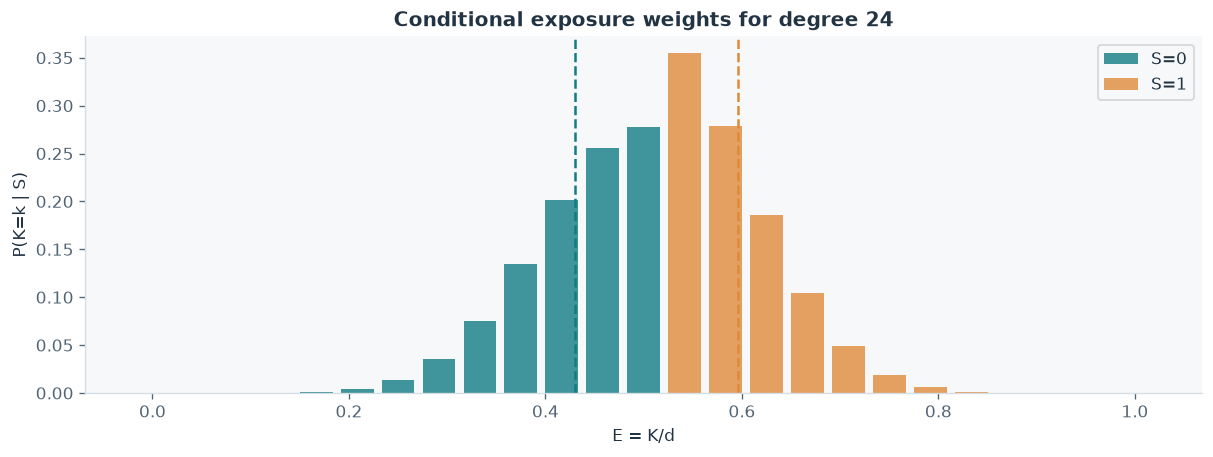

,状态 S,P(S),E[E | S]
0,0,0.5806,0.4306
1,1,0.4194,0.5961


In [7]:
d = int(node['degree'])
k = np.arange(d+1)
e_grid = k/d
weights = np.vstack([conditional_count_weights(d,.5,s) for s in (0,1)])
np.testing.assert_allclose(weights.sum(1), [1,1])
exposure_means = weights @ e_grid
fig, ax = plt.subplots(figsize=(10,3.7), constrained_layout=True)
for s in (0,1):
    ax.bar(e_grid, weights[s], width=.8/d, color=COLORS[s], alpha=.8, label=f'S={s}')
    ax.axvline(exposure_means[s], color=COLORS[s], linestyle='--')
ax.set(title=f'Conditional exposure weights for degree {d}', xlabel='E = K/d', ylabel='P(K=k | S)')
ax.legend()
show(fig, FIGURES, '04_conditional_exposure_weights')
table(pd.DataFrame({'状态 S':[0,1], 'P(S)': [arm_probability(d,.5,s) for s in (0,1)],
                    'E[E | S]': exposure_means}))

## 06 · 四个 μ 怎样变成直接、溢出和总效应？

### 先把四个响应写出来

记 $b_i=1-X_i-3\overline X_{\mathcal N_i}$ 为基准部分，$\tau_i=a+0.2e^{X_i}$ 为自身处理系数，$e_{i,s}=\mathbb E[E_i\mid S_i=s]$ 为上一节的状态内平均暴露。当前 DGP 有

$$
\mu_i(t,s)=b_i+\tau_i t-0.9e_{i,s}.
$$

| 响应 | 公式 | 用销售员的例子读一遍 |
|---|---|---|
| $\mu_i(0,0)$ | $b_i-0.9e_{i,0}$ | 自己没有 AI，合作同事处于低暴露状态时的平均业绩 |
| $\mu_i(0,1)$ | $b_i-0.9e_{i,1}$ | 自己没有 AI，合作同事处于高暴露状态时的平均业绩 |
| $\mu_i(1,0)$ | $b_i+\tau_i-0.9e_{i,0}$ | 自己有 AI，合作同事处于低暴露状态时的平均业绩 |
| $\mu_i(1,1)$ | $b_i+\tau_i-0.9e_{i,1}$ | 自己有 AI，合作同事处于高暴露状态时的平均业绩 |

这四个量描述同一个节点在四种条件下的目标响应。一份观测数据并没有同时观察到它们；我们利用模拟真值核对估计是否正确。

### 每种效应是在比较什么？

| 效应 | 本代码采用的差分 | 变化的条件 | 保持的条件 |
|---|---|---|---|
| Direct | $\mu_i(1,0)-\mu_i(0,0)$ | 自己从没有 AI 变为有 AI | 同伴低暴露 |
| Spillover | $\mu_i(1,1)-\mu_i(1,0)$ | 同伴从低暴露变为高暴露 | 自己有 AI |
| Total | $\mu_i(1,1)-\mu_i(0,0)$ | 自己和同伴状态一起改变 | 同一节点、图与特征等任务条件 |

可以沿着路径 **00 → 10 → 11** 理解：第一步是 Direct，第二步是 Spillover，两步加起来是 Total。因此按这里的定义，Direct + Spillover = Total。

$\mu_i(0,1)$ 也参加训练。它可用于另一个对照 $\mu_i(0,1)-\mu_i(0,0)$，即“自己未接受处理时的溢出效应”，只是本版报告的 Spillover 选择了自己接受处理的情况。当前 DGP 没有处理与暴露的交互项，两种溢出差分相等；一般结果机制不必如此。

### ITE 和 ATE 又是什么？

- **ITE**：对每个节点分别计算上面三种效应。本项目这里的 ITE 是节点级的设计平均效应，已经平均掉状态内部的处理分配和零均值观测噪声。
- **ATE**：在一份数据中，对全部节点的某一种 ITE 再取平均。例如，直接 ATE 就是所有节点 Direct 的平均。

“节点级”不表示用该节点一次观测的 $Y$ 就能直接得到效应。测试时 PFN 先估计四个响应，再做差得到效应，最后与独立计算的模拟真值比较。


,状态,节点真值,解析核对
0,mu00,0.3453,0.3453
1,mu01,0.1964,0.1964
2,mu10,7.3236,7.3236
3,mu11,7.1746,7.1746


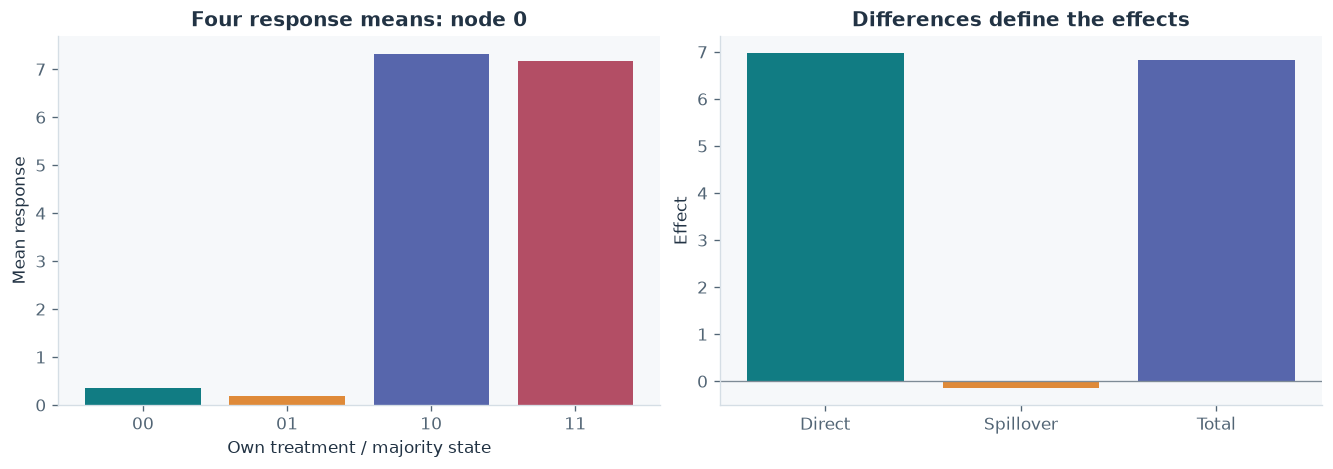

In [9]:
e_by_state = conditional_exposures(degree)
b = 1-observed['X'].to_numpy()-3*observed['neighbor_X'].to_numpy()
tau = a+.2*np.exp(observed['X'].to_numpy())
mu_analytic = np.column_stack([b+tau*t-.9*e_by_state[:,int(s)] for t,s in ARM_COORDINATES])
mu_truth = batch['oracle_arm_means'][0].numpy().reshape(N,4)
np.testing.assert_allclose(mu_analytic, mu_truth, rtol=1e-5, atol=1e-5)
true_effects = effects(mu_truth)
np.testing.assert_allclose(true_effects, batch['oracle_ite'][0].numpy(), rtol=1e-5, atol=2e-6)
np.testing.assert_allclose(true_effects[:,0]+true_effects[:,1],true_effects[:,2],atol=2e-6)
table(pd.DataFrame({'状态': ARM_NAMES, '节点真值': mu_truth[i], '解析核对':mu_analytic[i]}))
fig, axes=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
axes[0].bar(['00','01','10','11'],mu_truth[i],color=COLORS)
axes[0].set(title=f'Four response means: node {i}',xlabel='Own treatment / majority state',ylabel='Mean response')
axes[1].bar(EFFECT_LABELS,true_effects[i],color=[COLORS[0],COLORS[1],COLORS[2]])
axes[1].axhline(0,color='#7e8b96',lw=.8)
axes[1].set(title='Differences define the effects',ylabel='Effect')
show(fig,FIGURES,'06_four_means_and_effects')

**从这个 DGP 可以直接预期什么？**

- 直接效应为 $a+0.2e^{X_i}$，随任务系数和节点特征变化。
- 溢出效应为 $-0.9(e_{i,1}-e_{i,0})$，在固定图、固定处理设计下只随节点度数变化。
- 仅仅重新抽 $a$ 并不会让同一节点的溢出真值改变。
- Oracle 是模拟器真值，用于核对与评价；它不是能拿到真实数据上直接使用的估计器。

## 07 · 训练 / 验证 / 测试：切的是完整任务

一个任务是一整张网络上的一份 $X,T,Y$，模型从这个完整观测上下文回答该任务的查询。
本版图固定；不同任务重新抽取 $a,X,T,\epsilon$。

| 划分 | 正式默认数量 | 作用 |
|---|---:|---|
| train | 40,960 个完整网络任务 | 更新模型参数 |
| validation | 5,120 个完整网络任务 | 选择验证 NLL 最小的 checkpoint |
| test | 5 个种子 × 每种子 2 个任务 = 10 份 | 最后一次独立评价 |

训练 epoch 是重放同一个任务库；同一个任务不会因为进入下一个 epoch 就重新抽 $a$。
测试时允许使用当前任务的观测数据作为上下文，但不读真值、不更新模型参数。
**十份测试数据不是十张图，也不是训练十个 PFN。**

### 任务、epoch 和 checkpoint 分别指什么？

把一份任务理解为“一次完整的模拟实验”：1000 名销售员各有自己的特征、处理和结果。同一图上换一份任务，会重新生成这些数据和共享系数 $a$，不是只换一个节点。

**训练**用任务标签更新模型参数；**验证**选择保留哪个训练阶段的模型；**测试**在最终保留的模型上评价新任务。一个 epoch 是把既定训练任务库完整遍历一轮，checkpoint 是保存下来的模型参数及配置。测试时只加载权重作推断，不再利用测试真值训练模型。


### 四种 seed 的作用：与当前代码保持一致

| 配置 | 数值 | 控制什么 |
|---|---|---|
| 图种子 `seed` | 12345 | 生成固定的 ER1000 邻接矩阵；实际复现应直接读取保存的图文件 |
| 训练数据种子 `data_seed` | 12345 | 生成训练、验证任务中的特征、处理、噪声和任务系数；不同 split 使用独立随机流 |
| 模型训练种子 `train_seed` | 0 | 模型初始化及训练任务顺序等训练随机性 |
| 测试数据种子 `test_seeds` | 2025、2026、2027、2028、2029 | 每个种子生成 `task_id=0,1`，共 10 份独立测试数据 |

开头设置单元的 `DATA_SEED=2026` **只选定前面讲解的一份测试样本**，不是把训练数据种子改成 2026。原启动脚本中的环境变量 `DATA_SEED=12345` 对应训练数据种子，两处变量的使用范围不同。

下方小表用同一个数字种子 12345 演示 `train / validation / test` 三种 split 如何产生独立随机流；正式十份测试的种子安排仍为上表的 2025—2029。种子一致之外，图文件、DGP、模型配置和训练预算也要一致，才能对照结果。


In [10]:
split_rows=[]
for split in ['train','validation','test']:
    meta=coefficient_metadata(seed=12345,stream=f'scaling_v1/{split}',task_id=0)
    split_rows.append({'split':split,'data_seed':12345,'task_id':0,'本任务的 a':meta['a']})
table(pd.DataFrame(split_rows))
train_bank=TaskBank(GRAPH_FILE,CACHE,data_seed=12345,noise_sd=4.)
first=train_bank.task('train',0)
second=train_bank.task('train',0)
assert torch.equal(first['tokens'],second['tokens'])
assert not torch.equal(first['tokens'],train_bank.task('validation',0)['tokens'])
display(Markdown('**核对通过：** 同一任务重放得到相同观测数据；train 与 validation 使用独立随机流。'))

,split,data_seed,task_id,本任务的 a
0,train,12345,0,6.2971
1,validation,12345,0,6.5953
2,test,12345,0,4.8376


**核对通过：** 同一任务重放得到相同观测数据；train 与 validation 使用独立随机流。

## 08 · PFN 在做什么？输入、编码、查询、GMM

每个节点的观测 token 是
$$
[X_i,\ T_i,\ Y_i^{\rm obs},\ E_i,\ d_i/(N-1)].
$$

当前程序的网络路径是：

**观测 token + 邻接矩阵 → 自身／处理邻居／局部拓扑编码 → 标准自注意力 Transformer → 四个状态查询 → 共享 GMM head。**

`_network_aware_embedding` 使用一跳邻居及共同邻居的信息，将图结构编码到节点表示中；后续 `TransformerEncoderLayer` 使用标准自注意力，不再额外添加图结构偏置。
查询 $q=(t,s)$ 的作用是“询问该节点在指定状态下的平均响应”，不会把观测上下文中的真实处理列重写为查询处理。

| 张量 | 本例形状 | 含义 |
|---|---|---|
| tokens | `[1,1000,5]` | 一份任务的观测上下文 |
| adjacency | `[1,1000,1000]` | 同一任务的网络 |
| queries | `[1,1000,4,2]` | 每个节点的 00、01、10、11 查询 |
| cepo_target | `[1,1000,4]` | 训练监督或独立评测的真值 |
| GMM 参数 | `[1,1000,4,5]` | 每个响应的 5 个混合分量 |

真值只进入损失或评测。实际的模型调用只传入 tokens、queries、adjacency。

In [11]:
table(pd.DataFrame([{'对象': name, '实际形状': str(tuple(batch[name].shape))}
                    for name in ['tokens','adjacency','queries','cepo_target','oracle_arm_means']]))
np.testing.assert_array_equal(batch['queries'][0,0].numpy(),np.array(ARM_COORDINATES))

,对象,实际形状
0,tokens,"(1, 1000, 5)"
1,adjacency,"(1, 1000, 1000)"
2,queries,"(1, 1000, 4, 2)"
3,cepo_target,"(1, 1000, 4)"
4,oracle_arm_means,"(1, 1000, 2, 2)"


## 09 · 训练：先看配置，再决定是否重跑

训练损失为四个目标的等权负对数似然：
$$
\mathcal L=\frac14\sum_{(t,s)\in\{0,1\}^2}
-\log\left[\sum_{h=1}^5\pi_{i,t,s,h}\,
\mathcal N\big(\mu_i^{\rm truth}(t,s);m_{i,t,s,h},\sigma_{i,t,s,h}^2\big)\right],
$$
然后对任务和节点取平均。训练标签是无观测噪声的目标响应，观测噪声仍保留在输入 $Y$ 中。

下面直接调用项目训练入口，模型为 **10 层、128 维、4 heads、FFN=512**，训练配置集中在开头的 `TRAIN_CONFIG`。

默认 `RUN_TRAINING=False`，从 `CHECKPOINT_PATH` 加载你训练好的权重；仓库未附带这个主模型的 10 层权重。需要训练时，先设置 `DEVICE`，再改为 `RUN_TRAINING=True`，训练结果写入该权重所在目录。目录非空时程序会提示更换目录，避免覆盖已有实验。仅阅读图表时无需运行。

加载匹配权重后，以下代码会显示实际模型配置，并从该次运行的记录绘制训练曲线。

In [ ]:
selected_checkpoint = Path(CHECKPOINT_PATH).expanduser().resolve()
if RUN_TRAINING:
    selected_checkpoint = train(TRAIN_CONFIG, selected_checkpoint.parent)

if not selected_checkpoint.is_file():
    raise FileNotFoundError(
        f"未找到 10 层、128 维主模型：{selected_checkpoint}。"
        "请在开头填写已训练的 CHECKPOINT_PATH；或设置 DEVICE 后开启 RUN_TRAINING。"
        "只阅读时无需运行本单元格及后续模型计算。"
    )
model, state = load_model(selected_checkpoint, device=DEVICE)
model_config = state['model_config']
expected = {'num_layers': 10, 'd_model': 128, 'num_heads': 4, 'ffn_dim': 512}
if any(model_config.get(key) != value for key, value in expected.items()):
    raise ValueError('权重结构不匹配：本例使用 10 层、128 维、4 heads、FFN=512 的主模型。')
assert state['graph_record']['adjacency_sha256'] == graph_record['adjacency_sha256'], \
       '此主线要求同一张 ER1000 图；请勿把 ER300 或其他图的权重混入。'
assert float(state['config']['noise_sd']) == 4., '请核对 checkpoint 的 DGP 与噪声设置。'
# 按原评测入口核对数据／源码指纹，拒绝混用不匹配的数据机制。
model_bank = TaskBank(GRAPH_FILE, CACHE, data_seed=state['config']['data_seed'], noise_sd=4.)
assert model_bank.fingerprint == state['data_identity'], 'Checkpoint 与本版 DGP / 代码指纹不一致。'
model.eval()
model_label = f"PFN ({model_config['num_layers']} layers, {model_config['d_model']} dims)"
table(pd.DataFrame([
    {'设置': field, '当前权重': state['config'][field], '本例训练配置': getattr(TRAIN_CONFIG, field)}
    for field in ['train_tasks', 'validation_tasks', 'epochs', 'num_layers', 'd_model',
                  'num_heads', 'batch_size', 'data_seed', 'train_seed']
]))
cards([('本次载入模型', model_label), ('选中的 epoch', state['best_epoch']),
       ('参数量', f"{sum(p.numel() for p in model.parameters()):,}")])


In [ ]:
history_path=selected_checkpoint.parent/'history.jsonl'
if history_path.is_file():
    history=[json.loads(line) for line in history_path.read_text().splitlines() if line.strip()]
    epochs=[r['epoch'] for r in history]
    fig,ax=plt.subplots(figsize=(10,3.7),constrained_layout=True)
    ax.plot(epochs,[r['train']['total_loss'] for r in history],marker='o',label='Train NLL')
    ax.plot(epochs,[r['validation']['validation_gmm_nll'] for r in history],marker='o',label='Validation NLL')
    ax.axvline(state['best_epoch'],ls='--',color=COLORS[2],label='Selected checkpoint')
    ax.set(title=f'Training record — {model_label}',xlabel='Epoch',ylabel='Four-arm average NLL')
    ax.legend(); ax.grid(axis='y')
    show(fig,FIGURES,'07_training_curve')
else:
    display(Markdown('当前权重旁没有 `history.jsonl`，因此不绘制训练曲线；不会用其他运行的曲线代替。'))

**读曲线时注意：** checkpoint 按 validation NLL 选取，不按测试 RMSE 选取。
NLL 衡量整个预测分布；RMSE 衡量点预测，两者不是同一个指标。运行上方绘图代码后，曲线来自当前权重旁的训练记录。

## 10 · 推断：只给观测数据，得到四状态预测

下面显式构造一个只包含观测输入的字典，真值不会随这个字典传入模型。
GMM 点预测按分量权重求均值：
$$
\widehat\mu_i(t,s)=\sum_{h=1}^5\pi_{i,t,s,h}m_{i,t,s,h}.
$$
代码中四臂顺序为 `00,01,10,11`，可按此顺序 reshape 成 `[N,2,2]`。

In [ ]:
model_input={'tokens':batch['tokens'].to(DEVICE),'adjacency':batch['adjacency'].to(DEVICE)}
assert set(model_input)=={'tokens','adjacency'}
weights_before={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
started=time.perf_counter()
prediction=predict_mu_distributions(model,model_input)
inference_seconds=time.perf_counter()-started
mu_pred_tensor=(prediction['gmm_pi']*prediction['gmm_mu']).sum(-1)
mu_pred=mu_pred_tensor[0].detach().cpu().numpy()
assert mu_pred.shape==(N,4) and np.isfinite(mu_pred).all()
assert all(torch.equal(weights_before[k],v.detach().cpu()) for k,v in model.state_dict().items())
mu_for_interface=mu_pred.reshape(N,2,2)
pred_effects=effects(mu_pred)
np.testing.assert_allclose(pred_effects[:,0]+pred_effects[:,1],pred_effects[:,2],atol=2e-6)
cards([('预测响应形状',str(mu_for_interface.shape)),('效应形状',str(pred_effects.shape)),
       ('本机推断秒数',f'{inference_seconds:.3f}'),('测试时参数更新','0')])
table(pd.DataFrame({'状态':ARM_NAMES,'节点真值':mu_truth[i],
                    'PFN 预测':mu_pred[i],'预测减真值':mu_pred[i]-mu_truth[i]}))

In [ ]:
fig,axes=plt.subplots(1,4,figsize=(15,3.5),constrained_layout=True)
for j,ax in enumerate(axes):
    ax.scatter(mu_truth[:,j],mu_pred[:,j],s=8,alpha=.35,color=COLORS[j])
    lo=min(mu_truth[:,j].min(),mu_pred[:,j].min())
    hi=max(mu_truth[:,j].max(),mu_pred[:,j].max())
    ax.plot([lo,hi],[lo,hi],ls='--',color='#718096',lw=1)
    error=np.sqrt(np.mean((mu_pred[:,j]-mu_truth[:,j])**2))
    ax.set(title=f'{ARM_NAMES[j]} | RMSE={error:.3f}',xlabel='True mean response',ylabel='PFN predicted mean')
show(fig,FIGURES,'08_mu_predictions')

运行上方代码后，散点图中的虚线表示预测等于真值，偏离虚线反映预测误差。图中比较的是**平均响应**，不是含噪声的观测 $Y$；把预测响应直接与每个节点的 $Y$ 比较，会混入观测噪声和状态差异。

## 11 · GMM：模型输出不止一个数

每个状态有 5 个分量，各分量曲线相加得到混合密度。
这是模型对平均响应目标的分布表示，**不是邻居暴露的二项分布，也不是观测噪声分布**。
四个边际 GMM 不构成联合后验，不能直接假设相互独立来计算效应置信区间。

### GMM 密度曲线里的“多个峰”怎么理解？

模型为一个固定的“节点＋状态”预测 5 组高斯参数，按权重相加后形成一条密度曲线。5 个分量不是 5 个节点，也不是 5 次实际业绩；它们共同表达模型对同一个平均响应目标的分布预测。

下方代码可根据当前模型输出绘制分量与混合密度。最后报告的点估计是整个混合分布的均值。它可能位于峰与峰之间；分布预测与单个点预测用途不同，模型给出分布也不自动保证它已校准或具有可靠的频率覆盖率。


In [ ]:
from scipy.stats import norm
pi=prediction['gmm_pi'][0,i].detach().cpu().numpy()
means=prediction['gmm_mu'][0,i].detach().cpu().numpy()
sigmas=prediction['gmm_sigma'][0,i].detach().cpu().numpy()
np.testing.assert_allclose(pi.sum(-1),1,atol=1e-6)
assert np.all(sigmas>0)
fig,axes=plt.subplots(2,2,figsize=(11,6.5),constrained_layout=True)
for j,ax in enumerate(axes.flat):
    lo=min(np.min(means[j]-3*sigmas[j]),mu_truth[i,j]-1)
    hi=max(np.max(means[j]+3*sigmas[j]),mu_truth[i,j]+1)
    grid=np.linspace(lo,hi,450)
    components=pi[j,:,None]*norm.pdf(grid[None,:],means[j,:,None],sigmas[j,:,None])
    for h in range(5): ax.plot(grid,components[h],color=COLORS[j],alpha=.25,lw=1)
    ax.plot(grid,components.sum(0),color=COLORS[j],lw=2,label='Mixture density')
    ax.axvline(mu_truth[i,j],color='#18364d',ls='--',label='Truth')
    ax.axvline(mu_pred[i,j],color='#df8a39',ls=':',label='Predicted mean')
    ax.set(title=f'Node {i} / {ARM_NAMES[j]}',xlabel='Mean response',ylabel='Density')
    ax.legend(fontsize=8)
show(fig,FIGURES,'09_gmm_marginals')

## 12 · 十份测试数据：ITE 与 ATE 分别怎么算？

默认测试种子是 2025–2029，每个种子使用 task_id=0、1，合计 10 份，均保留原图。
对每种效应：

$$
\begin{aligned}\operatorname{RMSE}_{ITE}&=\sqrt{\frac1{10N}\sum_{r=1}^{10}\sum_{i=1}^N
(\widehat\tau_{ri}-\tau_{ri})^2},\\
\operatorname{RMSE}_{ATE}&=\sqrt{\frac1{10}\sum_{r=1}^{10}
(\overline{\widehat\tau}_r-\overline\tau_r)^2}.\end{aligned}
$$

前者评价节点级误差，后者先在每份数据内平均，再评价 10 个任务级误差。
RMSE 从原始误差计算，不是把各数据集 RMSE 简单平均。


## 13 · 完整基线与结果展示示例

项目中的 [`pfn_interference/evaluation.py`](../pfn_interference/evaluation.py) 已连接多个文献基线。

| 输出层级 | 比较方法 |
|---|---|
| ITE | Localized DR-Lasso、NSI、HyperSCI、TNet、CausalPFN（仅 Direct） |
| ATE | HT、Hájek、F、L、reg-net、TNet、CausalPFN（仅 Direct） |

这里使用与你的结果表一致的展示名称：`Hájek`（代码标签 `Haj`）、`CausalPFN`（代码标签 `causalPFN`），其余方法名按原表保留。

先按 [README](../README.md) 安装项目依赖。正式训练完成后，在项目根目录运行下面的命令。
这是操作示例，**不会由 Run All 自动执行**；请将权重和输出路径替换成自己的。

```bash
python -m pfn_interference evaluate \
  --checkpoint runs/training/model_best.pt \
  --output runs/evaluation \
  --device cpu --test-seeds 2025 2026 2027 2028 2029 --test-tasks 2
```

默认包含完整 baseline，拟合量较大；有对应环境可用 `cuda` 或 `musa`。
`all_results.csv` 是汇总表，逐节点和逐任务结果用于复核 RMSE。
如果使用不同的调参、训练 epoch 或共同支持子集，要同时记录这些设置。

### 结果示例的配置

下面两张表来自你提供的实验汇总，名称、数值及加粗位置均按原表保留。对应的结果机制是：

$$
Y_i(t,e)=1-0.9e+6t-X_i+0.2t\exp(X_i)-3\bar X_{\mathcal N(i)}+\epsilon_i,
\qquad \epsilon_i\overset{\mathrm{iid}}{\sim}\mathcal N(0,4^2),\quad \lambda=1.
$$

此处自身处理的常数系数固定为 $6$；当前代码采用每个任务随机生成 $a\sim\mathrm{Uniform}(4,8)$。这是结果展示示例，不是当前 Notebook 运行产生的结果。原表未附节点数、评测数据集数和实际训练／测试 seed，因此这里不替它补写；当前代码的 seed 约定见第 07、15 节。

**表头怎么读：** `Method` 是方法，`Effect` 是效应类型；`Direct`、`Spillover`、`Total` 分别对应直接、溢出、总效应。`MAE`、`RMSE` 是绝对误差与均方根误差；`Bias` 是“预测减真值”的平均值；`Mean Truth`、`Mean Pred` 是平均真值与平均预测。ITE 表在节点层面汇总误差，ATE 表先在每份数据内计算平均效应，再汇总其误差。

图中加粗位置沿用原表。`CausalPFN` 只列出 `Direct`，不补造缺少的效应结果。


### ITE Results

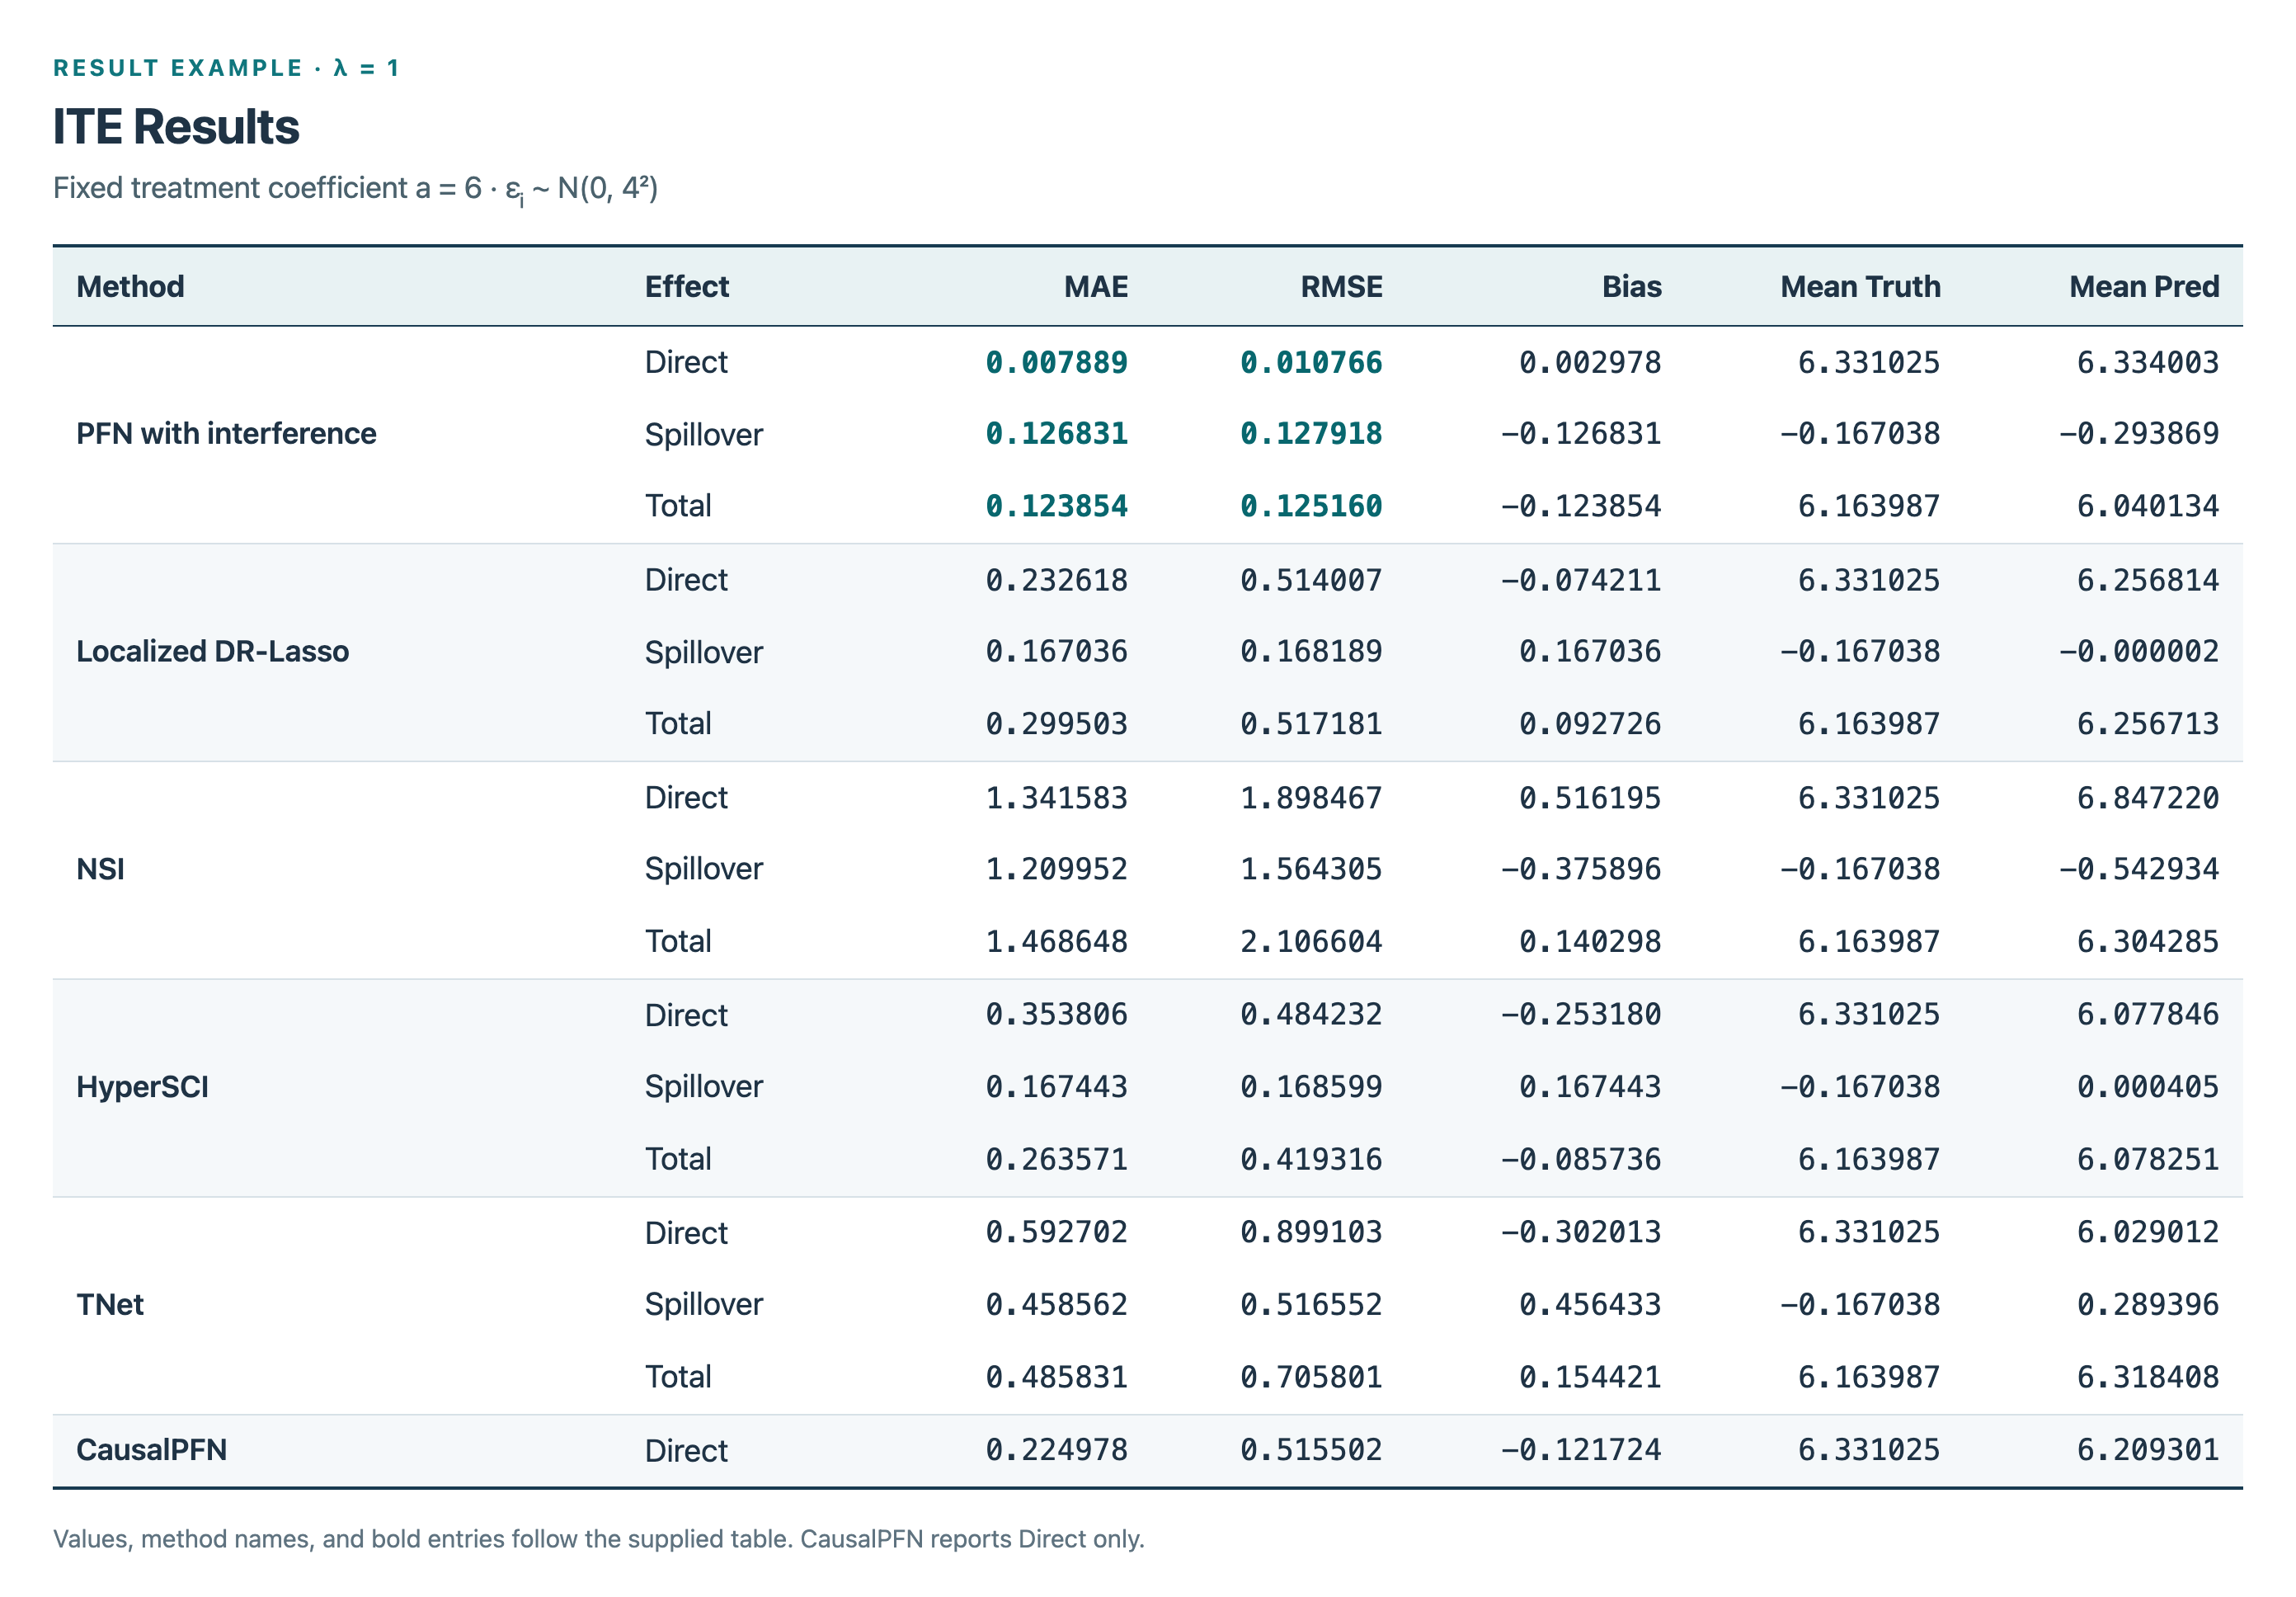

[查看对应 CSV 数据](results/user_example_ite_lambda1.csv)


### ATE Results

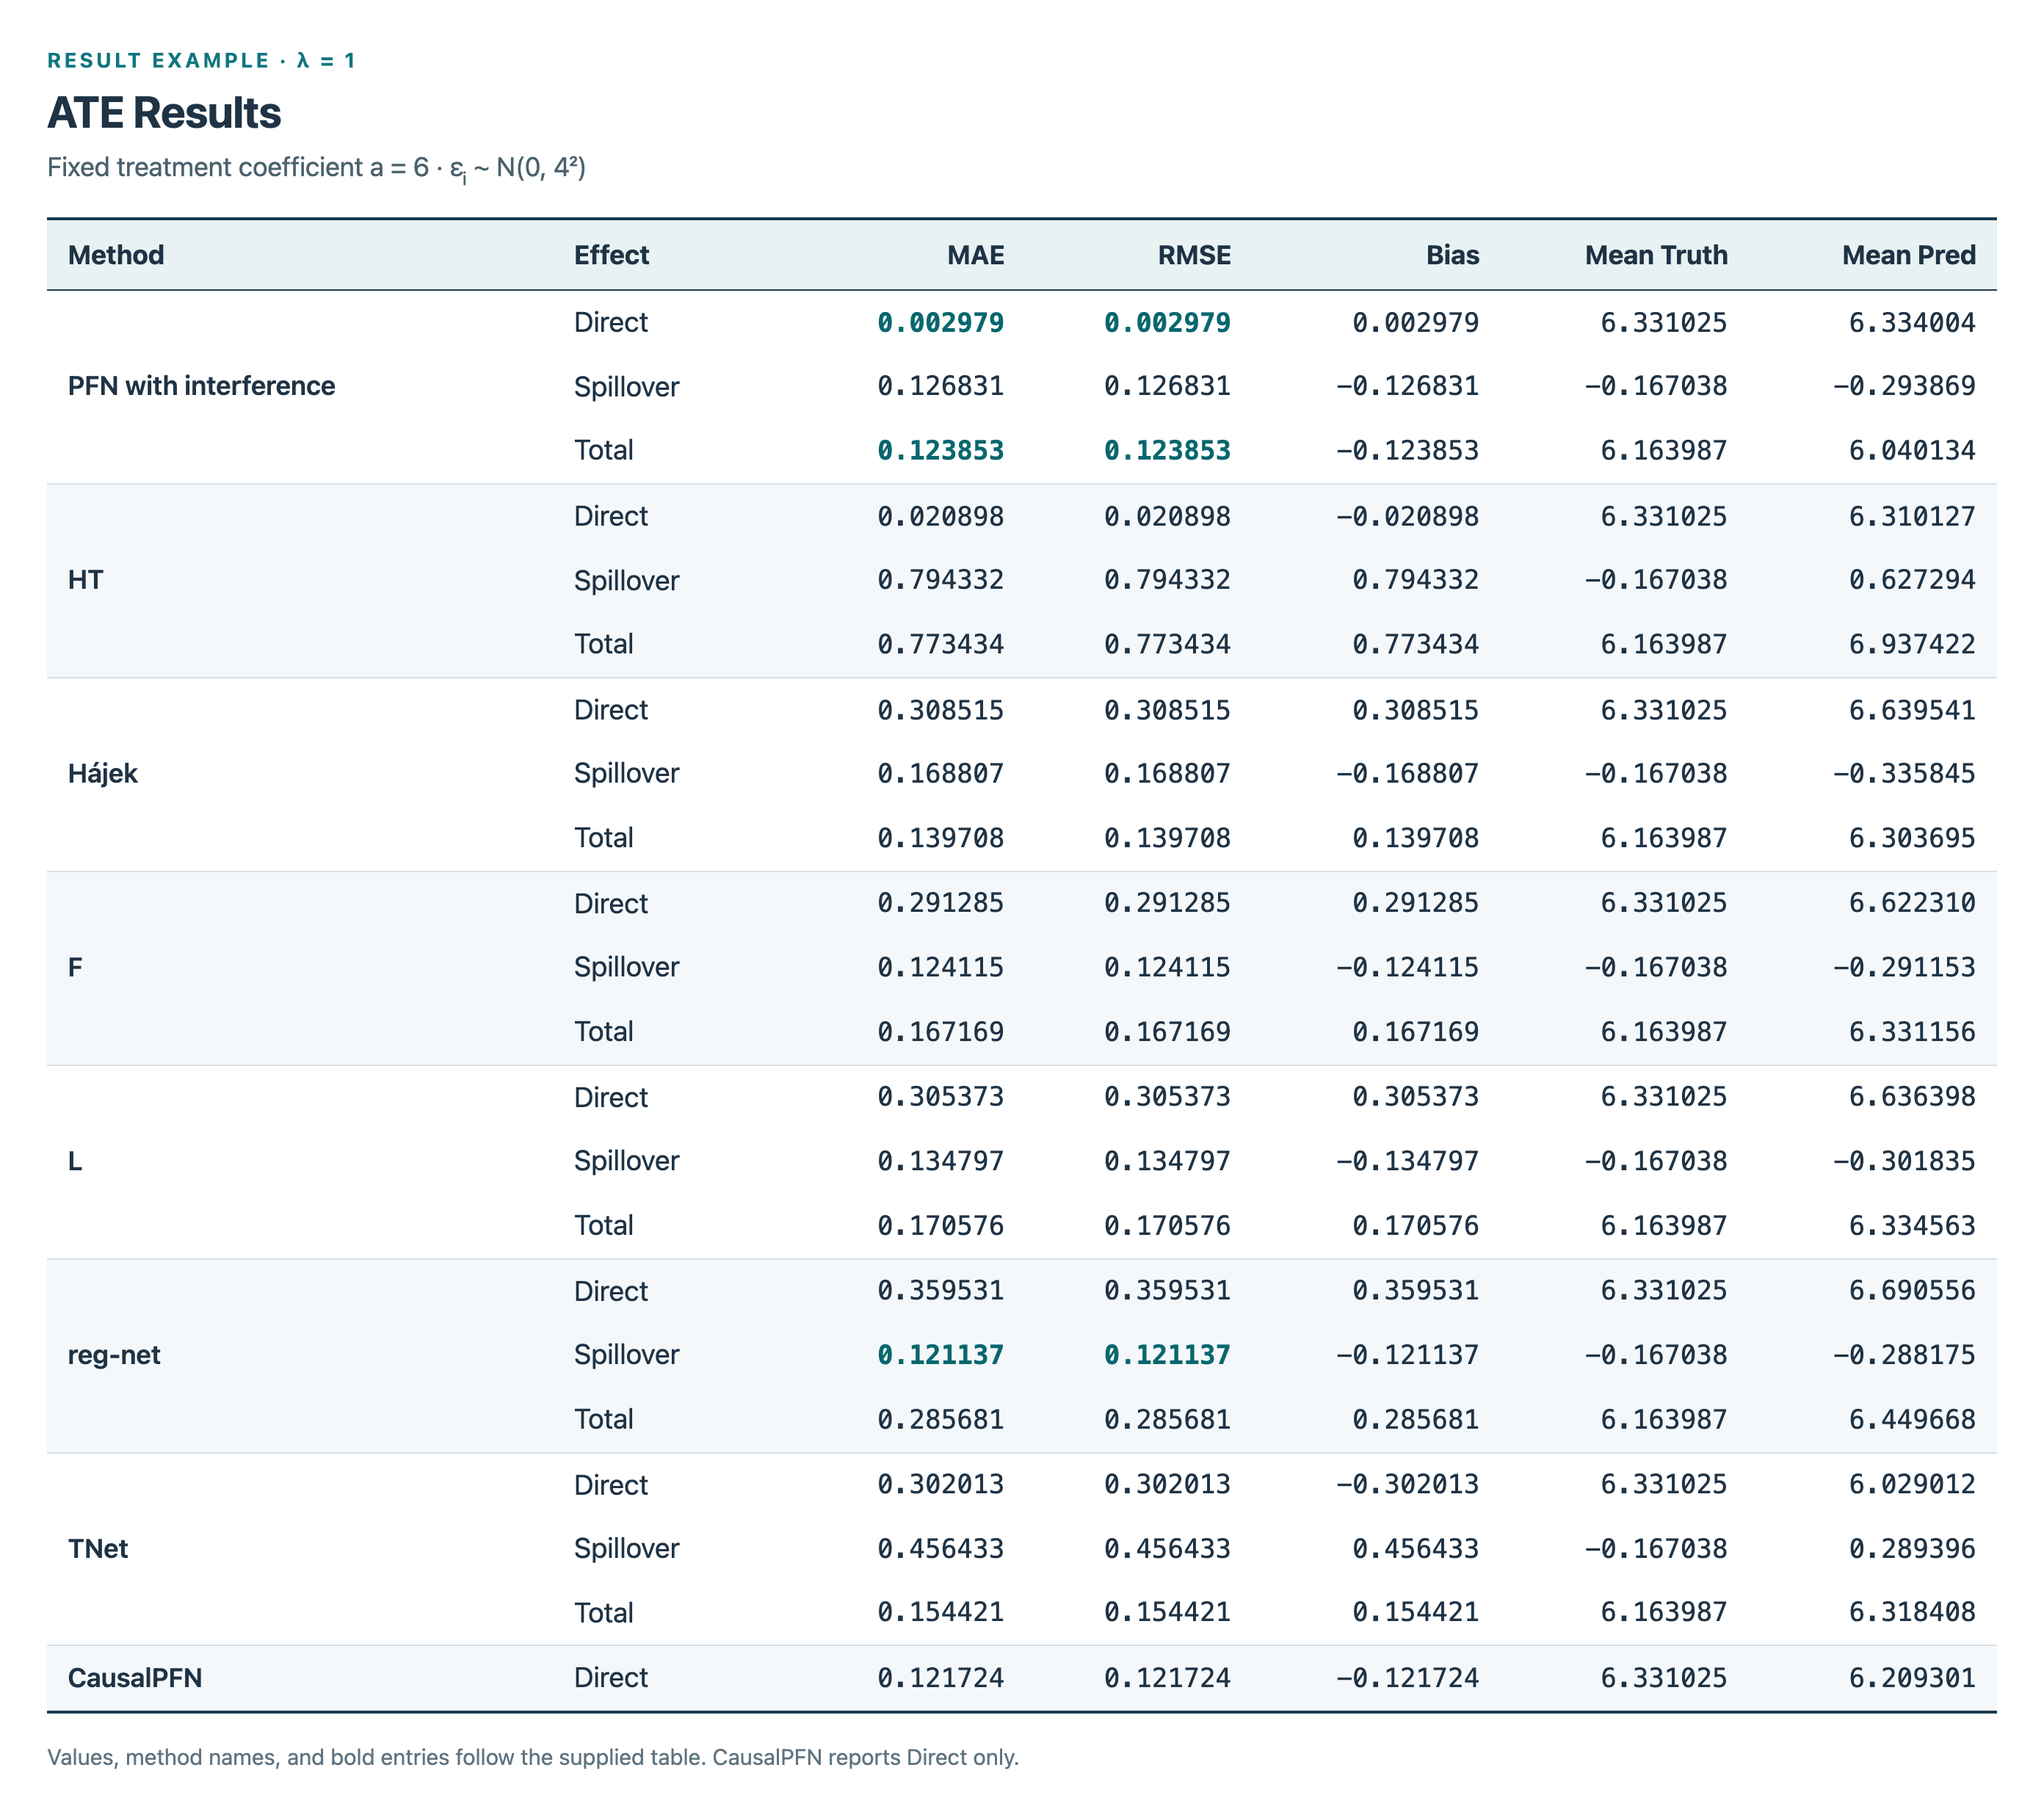

[查看对应 CSV 数据](results/user_example_ate_lambda1.csv)


## 14 · 换图时改哪里？

当前主实验读取固定 ER1000 图。更换图时，主要看三个入口：

| 位置 | 作用 |
|---|---|
| [graph.py](../pfn_interference/graph.py) 与 [data.py](../pfn_interference/data.py) | 查看图文件格式、邻接矩阵编码及校验；新图保持节点顺序一致，并满足无向、二元、无自环、无孤立节点的要求 |
| [dgp.py](../pfn_interference/dgp.py) 的 `generate_task(adjacency, ...)` | 接收新邻接矩阵，重新计算邻居特征、暴露、连续结果及真值 |
| [training.py](../pfn_interference/training.py) 的 `RunConfig.graph_file` | 指定新图文件；命令行对应 `--graph-file`，训练时使用新的输出目录 |

现有 `graph.py` 的生成入口用于 ER 图；其他图需要先按同一读取格式保存。正式评测会从 checkpoint 读取训练图；更换测试 seed 只改变该图上的数据，不会更换图。


## 15 · 实验配置与结果文件

### 当前 ER1000 代码采用的配置

Notebook 的训练代码与主入口统一使用下列配置。

| 项目 | 当前训练与评测配置 |
|---|---|
| 固定图 | ER，1000 节点，连边概率 0.02，图 seed=12345 |
| 处理设计 | 独立 Bernoulli(0.5) |
| 连续结果 DGP | `linear_b_random_a`，每任务 `a ~ Uniform(4,8)`，噪声标准差 4 |
| 暴露状态 | 比例不超过一半为低，严格超过一半为高 |
| Transformer | 10 层、128 维、4 heads、FFN=512 |
| GMM | 四状态各 5 个分量 |
| 训练 / 验证任务数 | 40960 / 5120 |
| 训练 epoch | 125 |
| batch size | 每进程 16；Notebook 单进程，服务器脚本默认 8 个 MUSA 进程 |
| 数据种子 `data_seed` | 12345 |
| 模型训练种子 `train_seed` | 0 |
| 测试种子 | 2025、2026、2027、2028、2029 |
| 每个测试种子的任务 | `task_id=0,1`，共 10 份数据 |
| 选模 | 验证集四状态平均 NLL 最小 |

这是代码配置，并不表示已完成该次训练。第 13 节的 ITE / ATE 表是另行提供的固定系数结果示例。

配置依据：[train.sh](../scripts/train.sh)、[evaluate.sh](../scripts/evaluate.sh)、[training.py](../pfn_interference/training.py)。每次实验实际配置以运行目录中的 `manifest.json` 和 `test_datasets.csv` 为准。

### 输出文件的作用

| 文件 | 内容 |
|---|---|
| `runs/training/manifest.json` | 实际图、DGP、模型、训练规模和 seed 配置 |
| `runs/training/model_best.pt` | 按验证 NLL 选择的模型及其配置 |
| `runs/evaluation/test_datasets.csv` | 实际测试数据集编号、测试种子、任务编号及图摘要 |
| `runs/evaluation/all_results.csv` | 主模型与基线的 ITE / ATE 汇总指标 |
| `runs/evaluation/linear_b_random_a/ite_unit_results.csv` | 节点级真值、预测与方法信息 |
| `runs/evaluation/linear_b_random_a/ate_graph_results.csv` | 数据集级真值、预测与方法信息 |

上述路径对应 README 中的默认命令；使用自定义 `--output` 时，以实际输出目录为准。Notebook 的图解位于 `figures/`，所附结果示例的 CSV 位于 `results/`。
